# HW10 Part 1: Data preparation
**Project F1: Moodle Activity, Denis Artemjev**

Here we make one table for the whole team. One row is one student in one year. It has the target (did the student fail or not) and the features that the models use.

The code that makes the table is in `src/prepare.py`. Ander and I load the table with the same function, so we all use the same data:

```python
from src.prepare import build_features
```

In [1]:
import os
import sys
sys.path.append("..")   # so that Python finds the src folder

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.prepare import build_features, COMPONENT_GROUPS

os.makedirs("../results/figures", exist_ok=True)   # folder for poster figures

df = build_features("../data")

print(df.shape)
df.head()

(843, 17)


,year,actor_id,fail,is_repeat,active_days,active_weeks,first_day_lag,active_weeks_share,active_days_last_2_weeks,days_forum,days_grades,days_homework,days_lectures,days_materials,hw_early_count,hw_early_submitted_share,hw_early_mean
0,2019,S027cf9,0,0,18,6,19,0.666667,5,0,1,18,0,4,5,1.0,83.8
1,2019,S032255,0,0,6,5,21,0.555556,2,1,0,6,0,2,5,0.4,4.4
2,2019,S03a8b8,0,0,30,8,0,0.888889,9,1,16,22,0,10,5,1.0,106.4
3,2019,S04cf7f,0,0,21,9,6,1.000000,7,0,5,18,0,3,5,1.0,94.4
4,2019,S05f285,1,0,32,7,7,0.777778,13,2,25,25,0,12,5,1.0,86.2


The table has 843 rows. These are all students with grades from 2019 and 2021–2026. 2020 is not in the table, because there are no grades for 2020.

## 1. What we did with the data

In CRISP-DM data preparation has five steps: select, clean, construct, integrate and format. This is what we did in each step. Most of these decisions come from HW7.

**Select**
- We removed 2020, because there are no grades, so we don't know who failed.
- We only use Moodle events from before the cutoff. The cutoff is one week before the first midterm. The teacher would use the prediction at this time, so later data can't be used. If we used it, the model would see the future (data leakage).
- We only use student events. Teacher events (`T`) are not used here.

**Clean**
- We count activity in active days, not in events. About 15% of events look like duplicates, and one student has more than 10,000 events. Active days don't change because of this.
- Students who have no events get 0 activity. They are in the grades table, so we keep them.

**Construct**
- Target `fail`: 1 if the grade is F or empty (the student did not come to the exam), 0 if the grade is A–E.
- 14 features about Moodle activity and early homework (see part 3).

**Integrate**
- We join the three tables. The cutoff comes from the calendar, the target from grades, and the activity from events.

**Format**
- Every task has an English and an Estonian score column. We keep one column with the higher score.
- We count weeks from the first day when any student was active in that year, because in some years students got access to Moodle later.

## 2. English and Estonian scores

In HW7 we found 584 cases where a student has both an English and an Estonian score for the same task. We said we would check them more closely.

In [2]:
import glob

# Read the raw grades again (before the two columns are joined)
files = sorted(glob.glob("../data/2*/grades.csv") + glob.glob("../data/data/2*/grades.csv"))
raw_grades = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

both = []
for col in raw_grades.columns:
    if col.endswith("_eng"):
        task = col[:-4]
        rows = raw_grades[raw_grades[col].notna() & raw_grades[task + "_est"].notna()]
        for eng, est in zip(rows[col], rows[task + "_est"]):
            both.append({"task": task, "eng": eng, "est": est})
both = pd.DataFrame(both)

print("cases with both scores:", len(both))
print("one of the two scores is 0:", ((both["eng"] == 0) | (both["est"] == 0)).sum())
print("both scores are equal:", (both["eng"] == both["est"]).sum())
both.head()

cases with both scores: 584
one of the two scores is 0: 544
both scores are equal: 50


,task,eng,est
0,homework_01,0.0,99.0
1,homework_01,0.0,110.0
2,homework_01,0.0,99.0
3,homework_01,0.0,88.0
4,homework_01,0.0,99.0


In 544 of the 584 cases one of the scores is 0. So the 0 is just an empty cell in the other language, and the real score is the other one. This means that taking the higher score is correct.

## 3. Features

Moodle tools changed over the years. For example, homework was a Quiz in 2021–2022 and an Assignment in other years. So we put the components into five groups, and count the days for each group. Marina uses the same groups.

In [3]:
# Which Moodle component is in which group
pd.Series(COMPONENT_GROUPS, name="group").sort_values()

Forum                          forum
User report                   grades
Overview report               grades
Assignment                  homework
Quiz                        homework
File submissions            homework
Online text submissions     homework
BigBlueButton               lectures
BigBlueButtonBN             lectures
File                       materials
URL                        materials
Folder                     materials
Page                       materials
Name: group, dtype: str

These are the columns of the table:

- `year`, `actor_id`: which student and which year (not used as features)
- `fail`: **the target**, 1 = F or no grade, 0 = A–E
- `is_repeat`: 1 if the student already took the course in an earlier year
- `active_days`: on how many days the student did something in Moodle before the cutoff
- `active_weeks`: in how many weeks the student was active
- `active_weeks_share`: the same as a share of all weeks before the cutoff (years have a different number of weeks)
- `first_day_lag`: how many days after the start the student was active for the first time
- `active_days_last_2_weeks`: active days in the last 14 days before the cutoff
- `days_materials`, `days_homework`, `days_lectures`, `days_forum`, `days_grades`: on how many days the student used each group of tools
- `hw_early_count`: how many homeworks had a deadline before the cutoff (3–5 in a year)
- `hw_early_submitted_share`: what share of these homeworks the student submitted
- `hw_early_mean`: the mean score of these homeworks (a missing homework is 0 points)

In HW7 we decided to compare a model with only activity features and a model with activity and early homework. That is why the homework features are separate.

## 4. Checks

First we check that there are no missing values.

In [4]:
print("missing values:", df.isna().sum().sum())

missing values: 0


Then we look at how many students failed in each year.

In [5]:
by_year = df.groupby("year").agg(students=("fail", "size"),
                                 fails=("fail", "sum"),
                                 fail_share=("fail", "mean"),
                                 early_homeworks=("hw_early_count", "first"))
by_year.round(3)

,students,fails,fail_share,early_homeworks
year,,,,
2019,114,12,0.105,5
2021,142,21,0.148,5
2022,83,10,0.120,3
2023,106,22,0.208,4
2024,119,17,0.143,5
2025,137,28,0.204,4
2026,142,17,0.120,5


About 15% of students fail, so the classes are imbalanced. The share is different in different years: from 10% in 2019 to about 20% in 2023 and 2025. The number of early homeworks is also different (3 to 5).

## 5. Students who passed vs students who failed

Here we compare the median of every feature for students who passed and students who failed.

In [6]:
features = df.columns.drop(["year", "actor_id", "fail"])

medians = df.groupby("fail")[features].median().T
medians.columns = ["pass", "fail"]
medians

,pass,fail
is_repeat,0.0,0.000000
active_days,23.0,13.000000
active_weeks,8.0,7.000000
first_day_lag,2.0,3.000000
active_weeks_share,1.0,0.777778
active_days_last_2_weeks,6.0,3.000000
days_forum,2.0,1.000000
days_grades,3.0,1.000000
days_homework,14.0,7.000000
days_lectures,4.0,1.000000


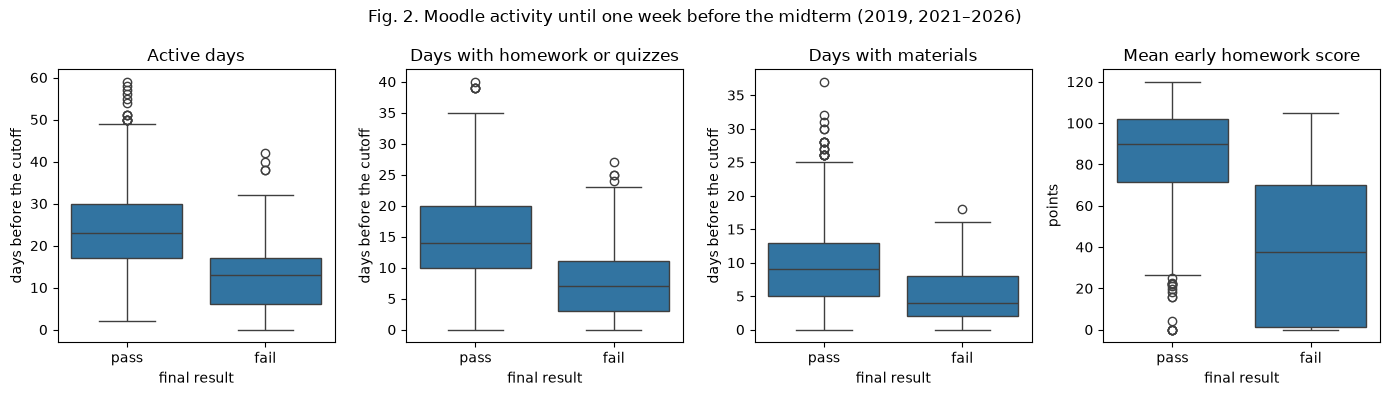

In [7]:
plot_data = df.copy()
plot_data["result"] = plot_data["fail"].map({0: "pass", 1: "fail"})

columns = ["active_days", "days_homework", "days_materials", "hw_early_mean"]
titles = ["Active days", "Days with homework or quizzes", "Days with materials", "Mean early homework score"]
y_labels = ["days before the cutoff", "days before the cutoff", "days before the cutoff", "points"]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col, title, y_label in zip(axes, columns, titles, y_labels):
    sns.boxplot(data=plot_data, x="result", y=col, order=["pass", "fail"], ax=ax)
    ax.set_title(title)
    ax.set_xlabel("final result")
    ax.set_ylabel(y_label)

fig.suptitle("Fig. 2. Moodle activity until one week before the midterm (2019, 2021–2026)")
plt.tight_layout()
plt.savefig("../results/figures/fig2_pass_vs_fail.pdf", bbox_inches="tight")
plt.show()

Students who failed were much less active before the cutoff. The median of active days is 23 for students who passed and 13 for students who failed. They also used homework tools and materials on about half as many days. The biggest difference is in early homework: the median score is 90 for students who passed and 37.5 for students who failed.

The groups still overlap, so some students who failed look like students who passed. This means that the models will make some mistakes.

There is one problem: online lectures (BigBlueButton) did not exist in 2019, so `days_lectures` is 0 for everyone in 2019. Marina's figures also show that the level of activity is different in different years. We check how much this matters in part 4, when we test the models on 2025 and 2026.

## 6. Save the table

We save the table into `data/processed/`. The `data` folder is in `.gitignore`, so the data is not published.

In [8]:
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/features.csv", index=False)
print("saved")

saved


## Summary

We made one table with 843 students (2019 and 2021–2026), the target `fail` and 14 features. We only use data from before the cutoff, one week before the first midterm, because this is when the teacher would use the prediction. Activity is counted in active days because of duplicate events and outliers, and Moodle tools are put into five groups because they changed over the years. Students who failed were clearly less active and had much lower early homework scores, so the features look useful for the models. About 15% of students fail, so the classes are imbalanced.